# Daily Challenge — Logistic Regression for Admission Prediction

In this challenge, I create a logistic regression model that uses two exam scores to predict if a student is admitted to university.

### What I learn here
- Data visualization with scatter plots.
- A basic understanding of logistic regression.
- Applying a logistic regression model to binary classification.
- Interpreting the results of logistic regression.

## How to run in Colab
1. Open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** → choose this file.
2. I keep `ex2data1.zip` in my `C:\Users\sivan\Datasets` folder. It holds the course file [ex2data1.txt](https://github.com/kaleko/CourseraML/blob/master/ex2/data/ex2data1.txt).
3. I run the cells from top to bottom. When the upload cell opens a file picker, I choose `ex2data1.zip`.

In [ ]:
from google.colab import files
# I import Colab's tool for uploading files from my computer.
uploaded = files.upload()
# I open a file picker and choose "ex2data1.zip".
!unzip "ex2data1.zip"
# I extract ex2data1.txt from the zip into Colab.

## Step 1 — Data Exploration

In this step, I load the dataset with pandas and look at the first few rows. Then I create a scatter plot of the exam scores, with admitted and not admitted students in different colors.

### What I learn here
- I load a text file that has no header row.
- I compare two groups on a scatter plot.

(100, 3)


,exam_1,exam_2,admitted
0,34.623660,78.024693,0
1,30.286711,43.894998,0
2,35.847409,72.902198,0
3,60.182599,86.308552,1
4,79.032736,75.344376,1


admitted
1    60
0    40
Name: count, dtype: int64


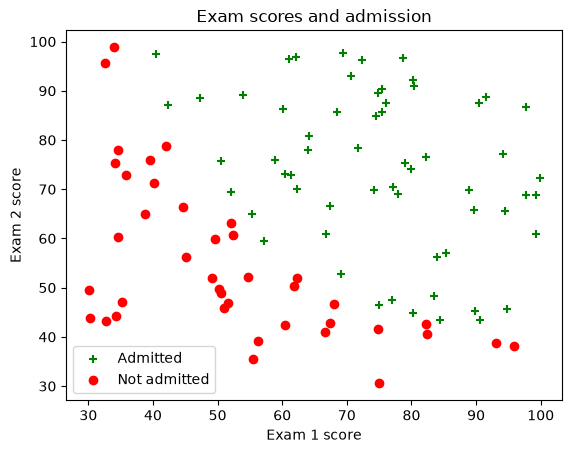

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# The file has no header row, so I give the three columns names myself.
students = pd.read_csv('ex2data1.txt', header=None, names=['exam_1', 'exam_2', 'admitted'])
print(students.shape)
display(students.head())
# I count the admitted (1) and not admitted (0) students.
print(students['admitted'].value_counts())

# I split the rows into the two groups.
admitted = students[students['admitted'] == 1]
not_admitted = students[students['admitted'] == 0]

plt.scatter(admitted['exam_1'], admitted['exam_2'], marker='+', color='green', label='Admitted')
plt.scatter(not_admitted['exam_1'], not_admitted['exam_2'], marker='o', color='red', label='Not admitted')
plt.xlabel('Exam 1 score')
plt.ylabel('Exam 2 score')
plt.title('Exam scores and admission')
plt.legend()
plt.show()

**What I see:** The printed shape shows 100 students, and the counts show 60 admitted and 40 not admitted. In the scatter plot, the admitted students (green +) are mostly in the upper-right part, where both exam scores are high, and the not admitted students (red o) are in the lower-left part. The two groups can be separated quite well by a straight line, so logistic regression fits this problem.

## Step 2 — Applying Logistic Regression with scikit-learn

In this step, I use `LogisticRegression` from scikit-learn to find the best parameters for my model, and I train it on my dataset.

### What I learn here
- I separate the features (exam scores) from the target (admitted).
- I train a model for a yes/no outcome and read its parameters.

In [2]:
from sklearn.linear_model import LogisticRegression

# X holds the two exam scores, y holds the answer (1 = admitted, 0 = not admitted).
X = students[['exam_1', 'exam_2']]
y = students['admitted']

model = LogisticRegression()
# fit() finds the best intercept and one coefficient for each exam.
model.fit(X, y)

print('Intercept:', model.intercept_)
print('Coefficients (exam_1, exam_2):', model.coef_)

Intercept: [-25.05219314]
Coefficients (exam_1, exam_2): [[0.20535491 0.2005838 ]]


## Step 3 — Making Predictions

In this step, I use my trained model to make predictions on my dataset, and I calculate the accuracy of my model.

### What I learn here
- I predict a class for every student.
- I calculate accuracy, the share of correct predictions.

In [3]:
from sklearn.metrics import accuracy_score

# I predict 0 or 1 for every student in the dataset.
predictions = model.predict(X)
print('First 10 predictions:', predictions[:10])

# Accuracy = correct predictions / all predictions.
accuracy = accuracy_score(y, predictions)
# By hand: (predictions == y).sum() / len(y)
print('Correct predictions:', (predictions == y).sum(), 'out of', len(y))
print('Accuracy:', accuracy)

First 10 predictions: [0 0 0 1 1 0 1 0 1 1]
Correct predictions: 89 out of 100
Accuracy: 0.89


## Step 4 — Model Evaluation

In this step, I interpret the result of my logistic regression and the accuracy of my model.

### What I learn here
- I explain what the coefficients mean.
- I explain what my accuracy tells me, and what it does not.

**Interpreting the parameters:** From the printed output of Step 2, the intercept is about **-25.05** and the coefficients are **0.205** for exam 1 and **0.201** for exam 2. Both coefficients are positive and almost equal, so a higher score in either exam raises the chance of admission, and the two exams count about the same. The model predicts "admitted" when the probability is above 0.5, which happens when -25.05 + 0.205 × exam_1 + 0.201 × exam_2 is above 0. For example, a student with about 62 in both exams is right on the boundary (-25.05 + 0.205 × 62 + 0.201 × 62 ≈ 0).

**Interpreting the accuracy:** The printed accuracy in Step 3 is **0.89**: my model predicts 89 of the 100 students correctly. This is much better than always guessing "admitted", which would only be right for the 60 admitted students (60%). The 11 mistakes are the students close to the boundary line in the scatter plot, where the two groups overlap. The challenge asks me to predict on the same data I trained on, so 89% is a training accuracy. With new students the accuracy would probably be a little lower, and to measure it I would need a separate test set.